# **Laboratory Activity 1: Coin Detection**

**Objective**: Use **convolution, spatial filtering, and edge detection techniques** to process images of
Philippine coins from the provided dataset and generate a clean edge-detected result where the
coins forming **₱21.10** can be clearly identified.

### **Step 1: Select, Load and Display the Selected Coins**
In this step, we select the coins that total **P21.10**, load them, then display for verification.


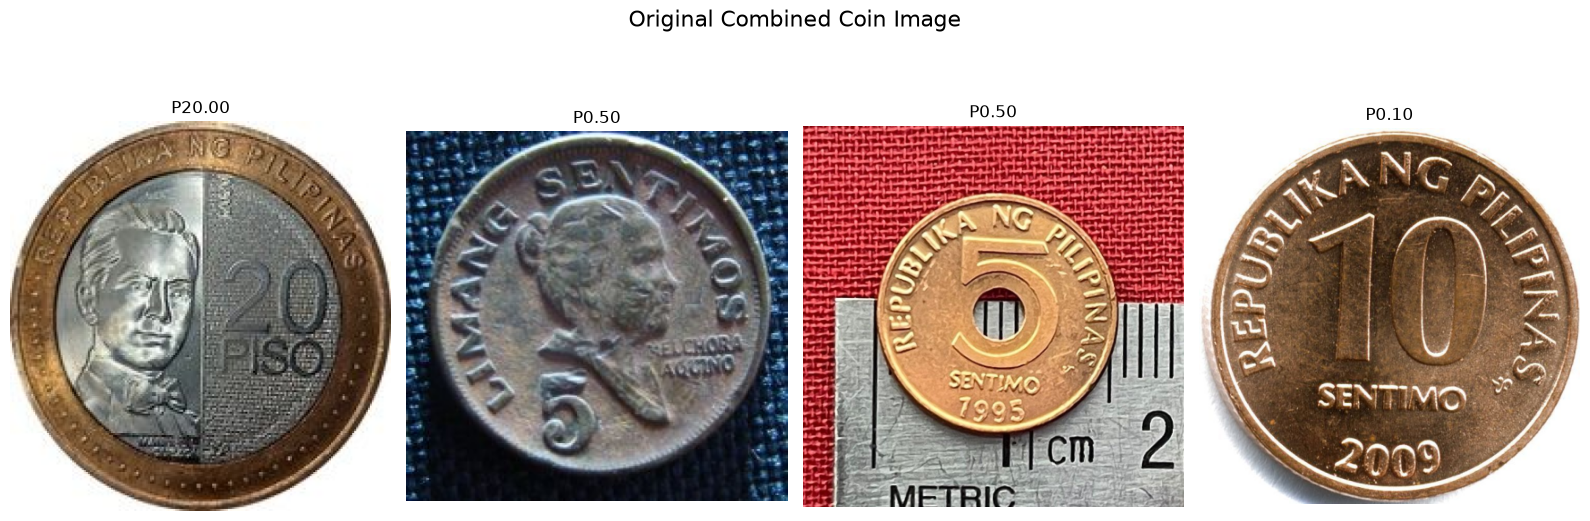

Coins selected: P20.00, P0.50, P0.50, P0.10 = P 21.1


In [3]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Coins selected: One 20-peso coin, two 50-centavo coins, and one 10-centavo coin
coin_files = [
    ("COINS/20.jpg", "P20.00"),
    ("COINS/.555.jpeg", "P0.50"),
    ("COINS/.5.jpeg", "P0.50"),
    ("COINS/File_2009phil10centobv_jpg - Wikimedia Commons.jpeg", "P0.10")
]

WORKSPACE_ROOT = Path(r"i:\4th year\SEM 1\Computer Vision")


def resolve_image_path(path):
    rel = Path(path)
    candidates = [
        Path.cwd() / rel,
        Path.cwd() / "Activity 1" / rel,
        WORKSPACE_ROOT / rel,
        WORKSPACE_ROOT / "Activity 1" / rel,
    ]

    for candidate in candidates:
        if candidate.is_file():
            return candidate

    raise FileNotFoundError(
        f"Could not find image '{path}'. Tried: "
        + "; ".join(str(candidate) for candidate in candidates)
    )


def load_rgb(path, target_h=420):
    resolved = resolve_image_path(path)
    img = cv2.imread(str(resolved))
    if img is None:
        raise FileNotFoundError(f"OpenCV could not read image: {resolved}")

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    scale = target_h / h
    img = cv2.resize(img, (int(w * scale), target_h), interpolation=cv2.INTER_AREA)
    return img


coin_imgs = [load_rgb(p) for p, _ in coin_files]
combined = cv2.hconcat(coin_imgs)

fig, axes = plt.subplots(1, len(coin_imgs), figsize=(16, 6))
for coin in range(len(coin_imgs)):
    axes[coin].imshow(coin_imgs[coin])
    axes[coin].set_title(coin_files[coin][1])
    axes[coin].axis("off")

fig.suptitle("Original Combined Coin Image", fontsize=16)
plt.tight_layout()
plt.show()

print("Coins selected: P20.00, P0.50, P0.50, P0.10 = P", sum([float(coin[1][1:]) for coin in coin_files]))

### **Step 2: Pre-Processing**
In this step, we convert the selected coins to grayscale and apply noise reduction to prepare them for **convolution** and **edge detection**.

Methods used:
- **Grayscale conversion**
- **Noise reduction using Median Filter and Gaussian Blur**

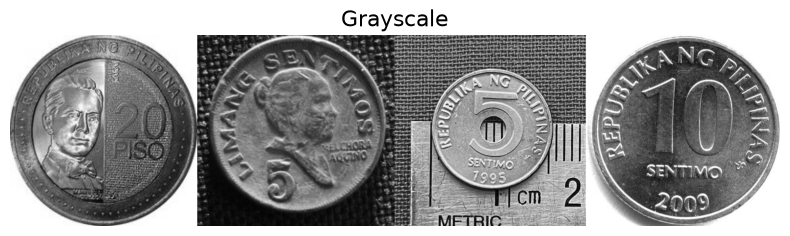

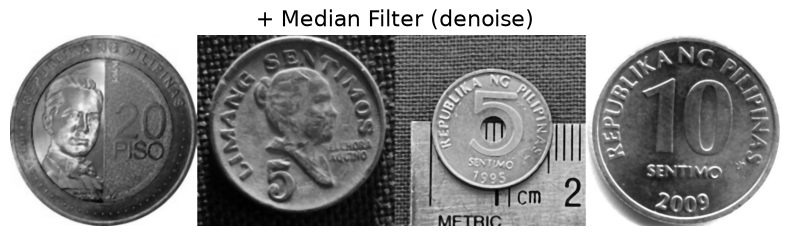

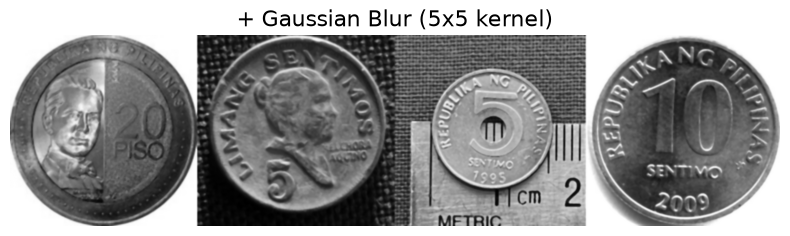

In [4]:
gray = cv2.cvtColor(combined, cv2.COLOR_RGB2GRAY)

# Noise reduction 1: Median Filter
median = cv2.medianBlur(gray, 5)

# Noise reduction 2: Gaussian smoothing kernel (applied as a convolution)
kernel_gaussian = np.array([
    [1,  4,  6,  4, 1],
    [4, 16, 24, 16, 4],
    [6, 24, 36, 24, 6],
    [4, 16, 24, 16, 4],
    [1,  4,  6,  4, 1]
], dtype=np.float32) / 256

filtered = cv2.filter2D(median, -1, kernel_gaussian)

stages = [
    (gray, "Grayscale"),
    (median, "+ Median Filter (denoise)"),
    (filtered, "+ Gaussian Blur (5x5 kernel)")
]

for image, title in stages:
    plt.figure(figsize=(8, 6))
    plt.imshow(image, cmap="gray")
    plt.title(title, fontsize=16)
    plt.axis("off")
    plt.tight_layout()
    plt.show()


### **Step 3: Apply Convolution**
In this step, we apply convolution to the pre-processed image using a **sharpening kernel** to enhance the edges of the coins.

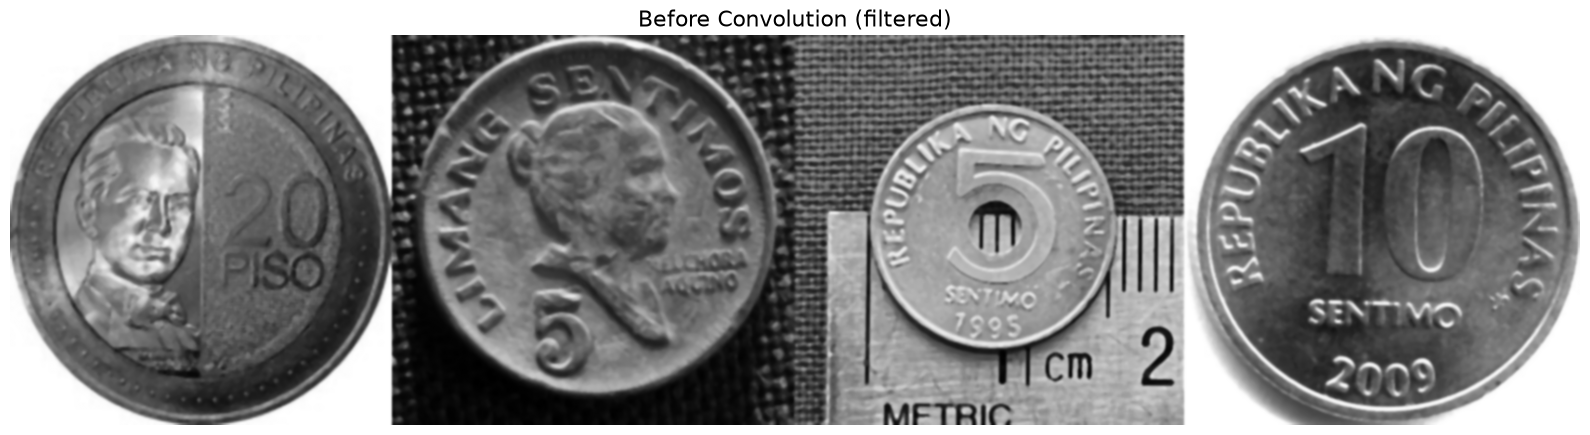

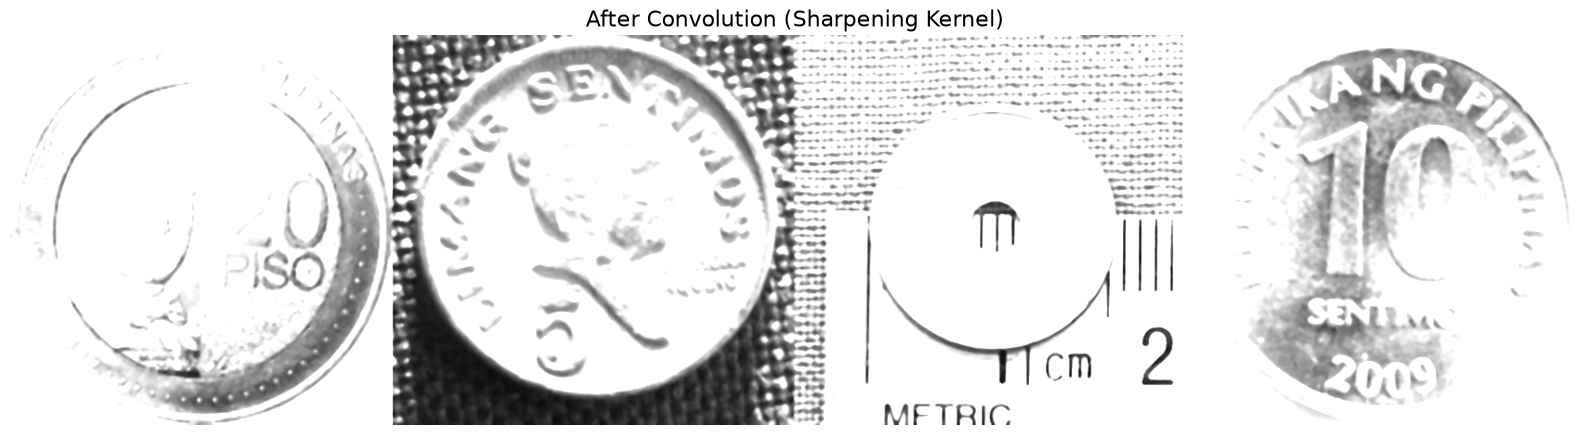

In [5]:
# Using kernel from the collab notebook sample
kernel = np.array([[0, -1, 0],
                   [-1, 7, -1],
                   [0, -1, 0]])

sharpened = cv2.filter2D(filtered, -1, kernel)  # openCV's filter2D function applies the convolution operation to the image using the specified kernel.

plt.figure(figsize=(16, 8))
plt.imshow(filtered, cmap="gray")
plt.title("Before Convolution (filtered)", fontsize=16)
plt.axis("off")
plt.tight_layout()
plt.show()

plt.figure(figsize=(16, 8))
plt.imshow(sharpened, cmap="gray")
plt.title("After Convolution (Sharpening Kernel)", fontsize=16)
plt.axis("off")
plt.tight_layout()
plt.show()

Using standard 9-point grid (3 × 3) sharpening kernel:
```
[[ 0, -1,  0],
 [-1,  5, -1],
 [ 0, -1,  0]]
```

This kernel is designed to sharpen the image by emphasizing the differences between neighboring pixel values, which helps in highlighting the edges of the coins.

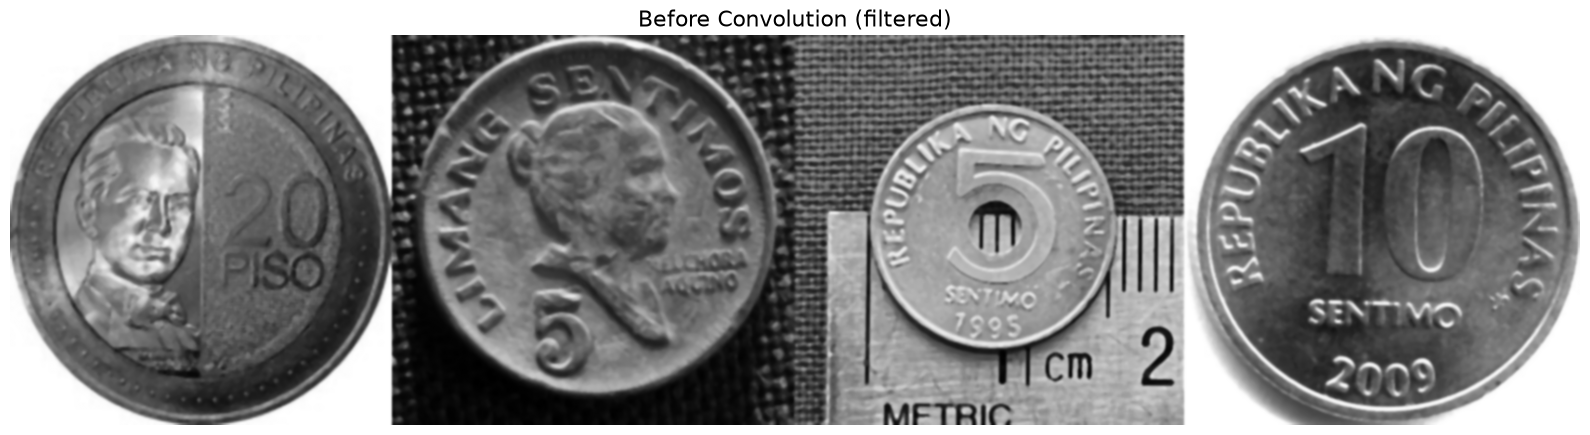

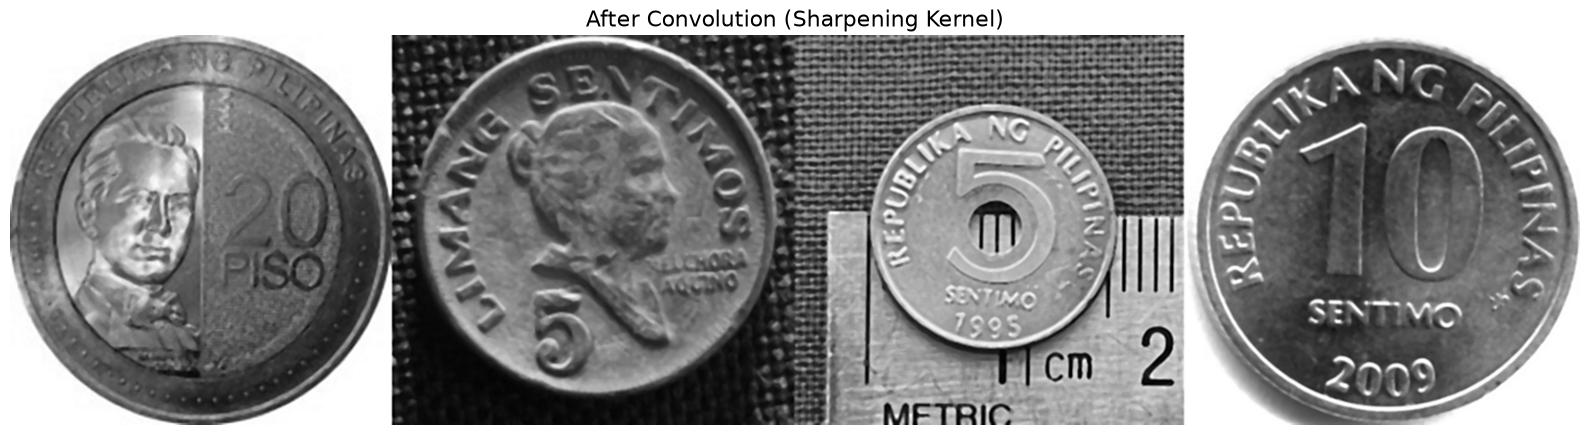

In [6]:
kernel = np.array([
    [ 0, -1,  0],
    [-1,  5, -1],
    [ 0, -1,  0]
], dtype=np.float32)

sharpened = cv2.filter2D(filtered, -1, kernel)  # openCV's filter2D function applies the convolution operation to the image using the specified kernel.

plt.figure(figsize=(16, 8))
plt.imshow(filtered, cmap="gray")
plt.title("Before Convolution (filtered)", fontsize=16)
plt.axis("off")
plt.tight_layout()
plt.show()

plt.figure(figsize=(16, 8))
plt.imshow(sharpened, cmap="gray")
plt.title("After Convolution (Sharpening Kernel)", fontsize=16)
plt.axis("off")
plt.tight_layout()
plt.show()

Since the standard kernel produces better sharpening and than the kernel used in the collab notebook-which resulted in high exposure and loss of details, we will use the standard kernel for this activity.

### **Step 4: Edge Detection**

In this step, we experiment with different edge detection methods to find the most effective one for detecting the edges of the coins.

Here, we apply **Canny** edge detection to the sharpened image to extract the edges of the coins.

Canny edge detection is a multi-stage algorithm that detects a wide range of edges in images. It involves the following steps:
1. Noise reduction using a Gaussian filter.
2. Finding the intensity gradient of the image.
3. Non-maximum suppression to get rid of spurious response to edge detection.
4. Hysteresis thresholding to track edges by suppressing all edges that are not connected to a very certain (strong) edge.

This process results in a binary image where the edges of the coins are highlighted, making it easier to identify and analyze them.

Source: [Edge Detection Using OpenCV](https://opencv.org/edge-detection-using-opencv/)

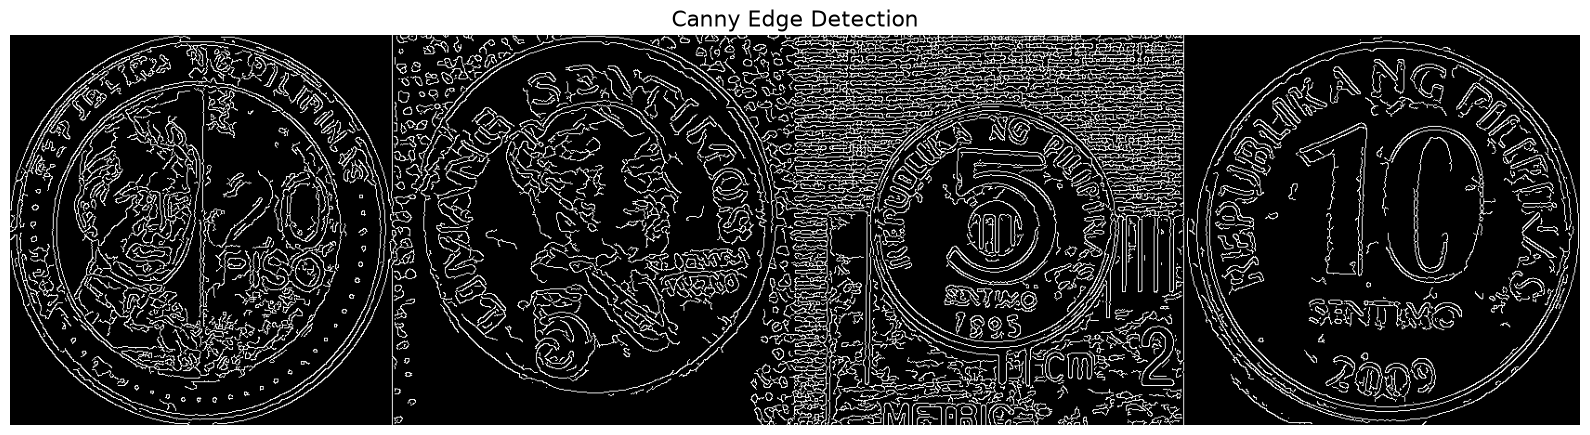

In [7]:
edges = cv2.Canny(sharpened, 40, 120)

plt.figure(figsize=(16, 6))
plt.imshow(edges, cmap="gray")
plt.title("Canny Edge Detection", fontsize=16)
plt.axis("off")
plt.tight_layout()
plt.show()

The second method we will try is the **Laplacian** edge detection, which uses the second derivative of the image to find regions of rapid intensity change. This method is sensitive to noise, so it is often preceded by a Gaussian smoothing step.

Source: [Edge Detection Using OpenCV](https://opencv.org/edge-detection-using-opencv/)

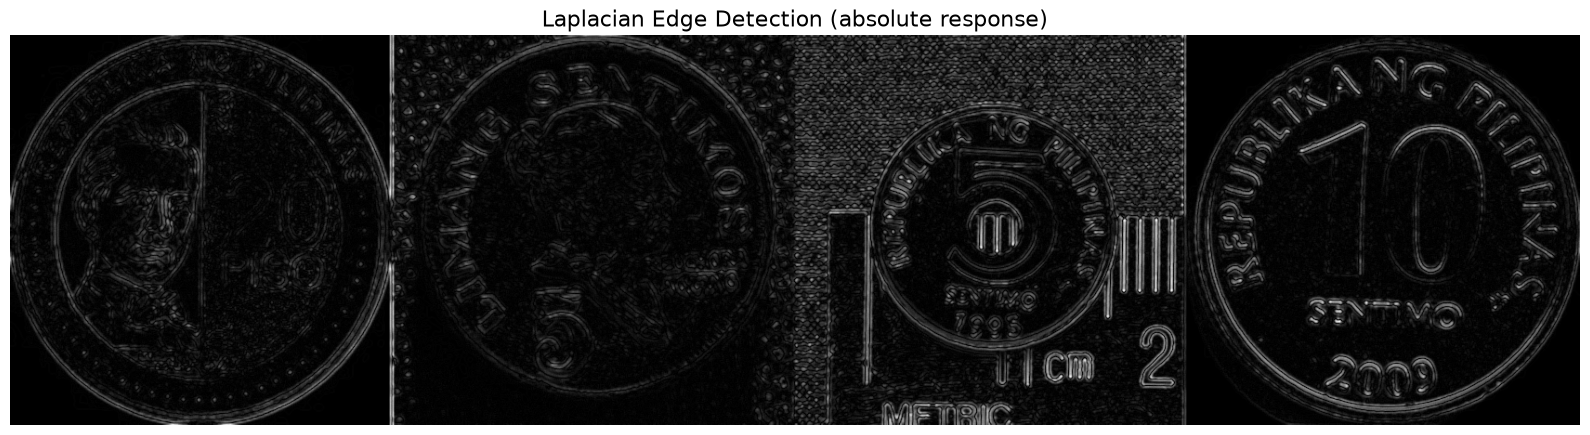

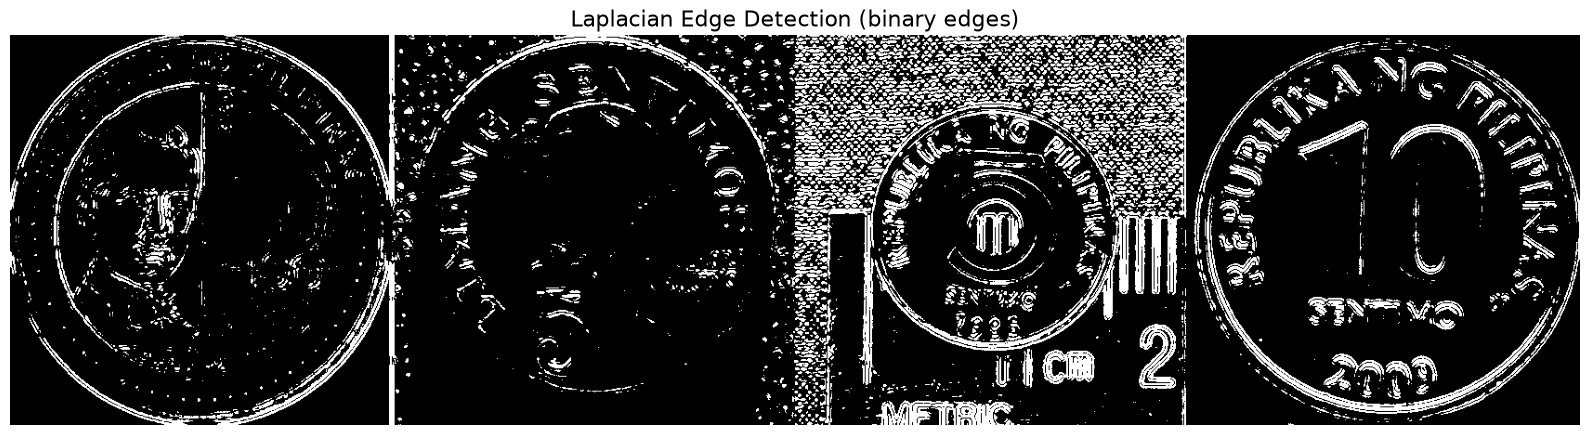

In [8]:
laplacian = cv2.Laplacian(filtered, cv2.CV_64F, ksize=3)
laplacian_abs = cv2.convertScaleAbs(laplacian)

# Convert to a binary edge map for next cleaning step
_, edges = cv2.threshold(laplacian_abs, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

plt.figure(figsize=(16, 6))
plt.imshow(laplacian_abs, cmap="gray")
plt.title("Laplacian Edge Detection (absolute response)", fontsize=16)
plt.axis("off")
plt.tight_layout()
plt.show()

plt.figure(figsize=(16, 6))
plt.imshow(edges, cmap="gray")
plt.title("Laplacian Edge Detection (binary edges)", fontsize=16)
plt.axis("off")
plt.tight_layout()
plt.show()

The third method we will try is using **Sobel**, which computes the gradient of the image intensity at each pixel, giving the direction of the largest possible increase from light to dark and the rate of change in that direction. It is also sensitive to noise, so it is often preceded by a Gaussian smoothing step.

Source: [Edge Detection Using OpenCV](https://opencv.org/edge-detection-using-opencv/)

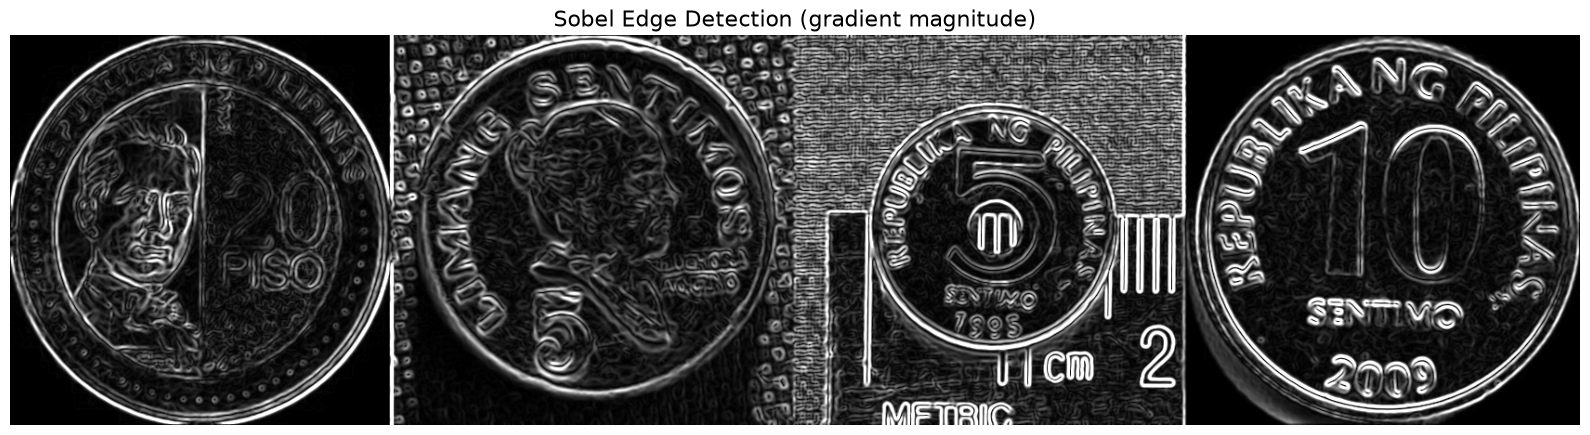

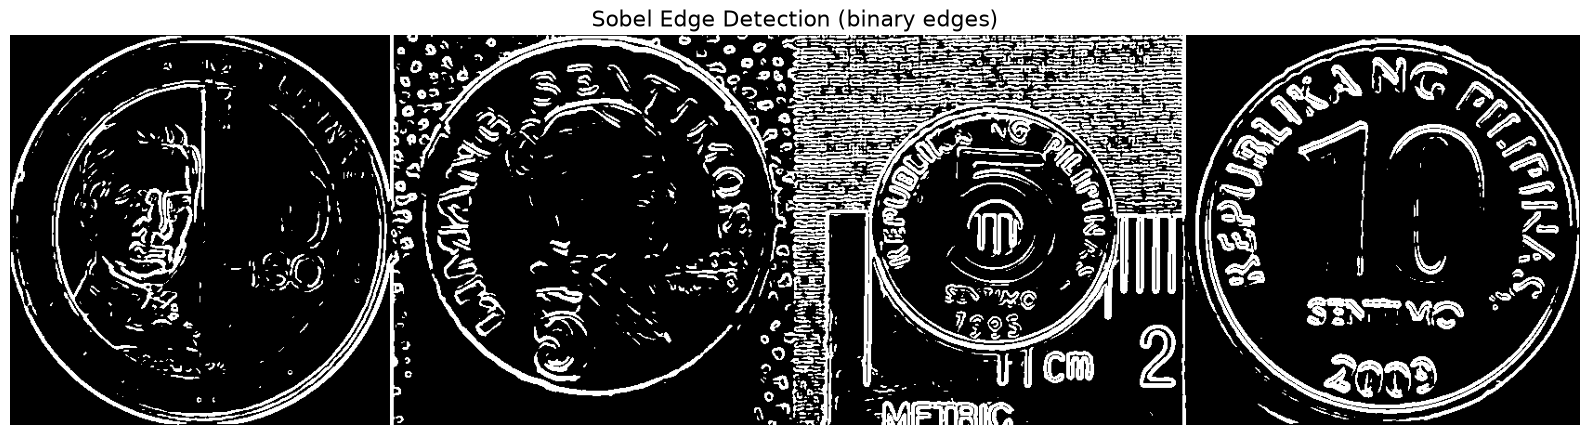

In [9]:
# Sobel edge detection on the smoothed image
sobel_x = cv2.Sobel(filtered, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(filtered, cv2.CV_64F, 0, 1, ksize=3)

sobel_mag = cv2.magnitude(sobel_x, sobel_y)
sobel_abs = cv2.convertScaleAbs(sobel_mag)

# Binary edge map (used by the next cleaning step)
_, edges = cv2.threshold(sobel_abs, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

plt.figure(figsize=(16, 6))
plt.imshow(sobel_abs, cmap="gray")
plt.title("Sobel Edge Detection (gradient magnitude)", fontsize=16)
plt.axis("off")
plt.tight_layout()
plt.show()

plt.figure(figsize=(16, 6))
plt.imshow(edges, cmap="gray")
plt.title("Sobel Edge Detection (binary edges)", fontsize=16)
plt.axis("off")
plt.tight_layout()
plt.show()

Upon visual inspection of the three edge detection methods (Canny, Laplacian, and Sobel), **Canny edge detection was found to be the most effective in producing clean, well-defined edges of the coins.** 

The results of the Laplacian and Sobel methods were less satisfactory, as they produced more noise -- especially of the background -- and less distinct edges compared to Canny.

### **Step 5: Clean the Result**

In this step, we clean the result of the edge detection to remove noise and small artifacts from the binary edge image using three different methods.

Methods used:
- **Connected-component labeling with area-based filtering** - this method identifies connected regions in the binary image and filters them based on their area, allowing the removal of small noise components that are not part of the coins.
- **Morphological operations** - these operations, such as dilation and erosion, are applied to the binary image to enhance the edges and remove small noise. Dilation can help to close gaps in the edges, while erosion can remove small noise points.
- **Contour detection** - this method detects the contours of the coins in the binary image, allowing for the identification and extraction of the coin shapes from the background.


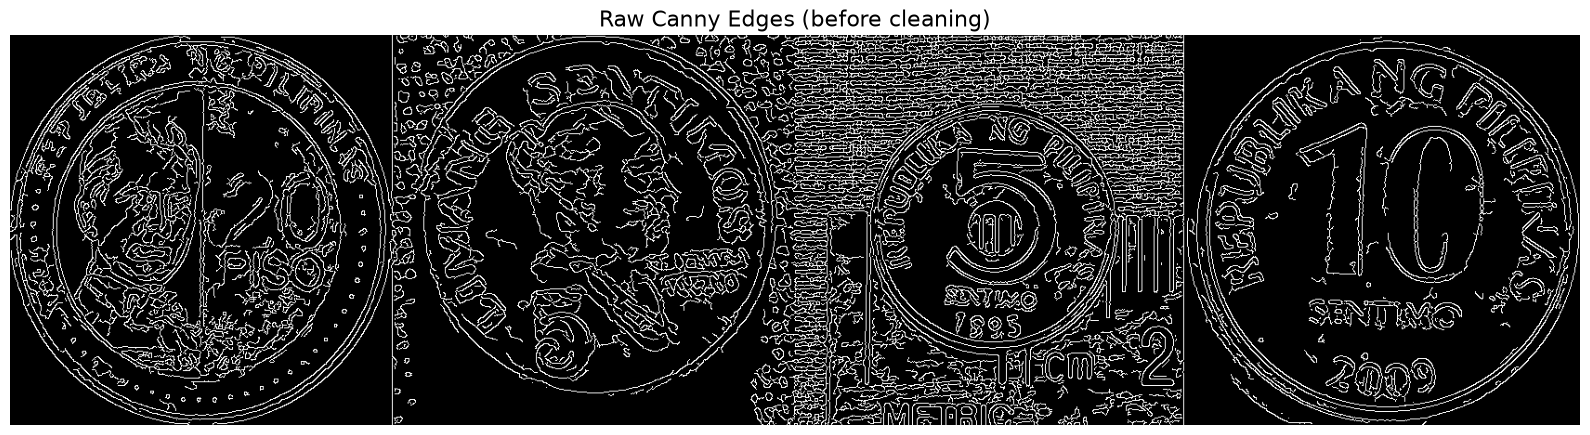

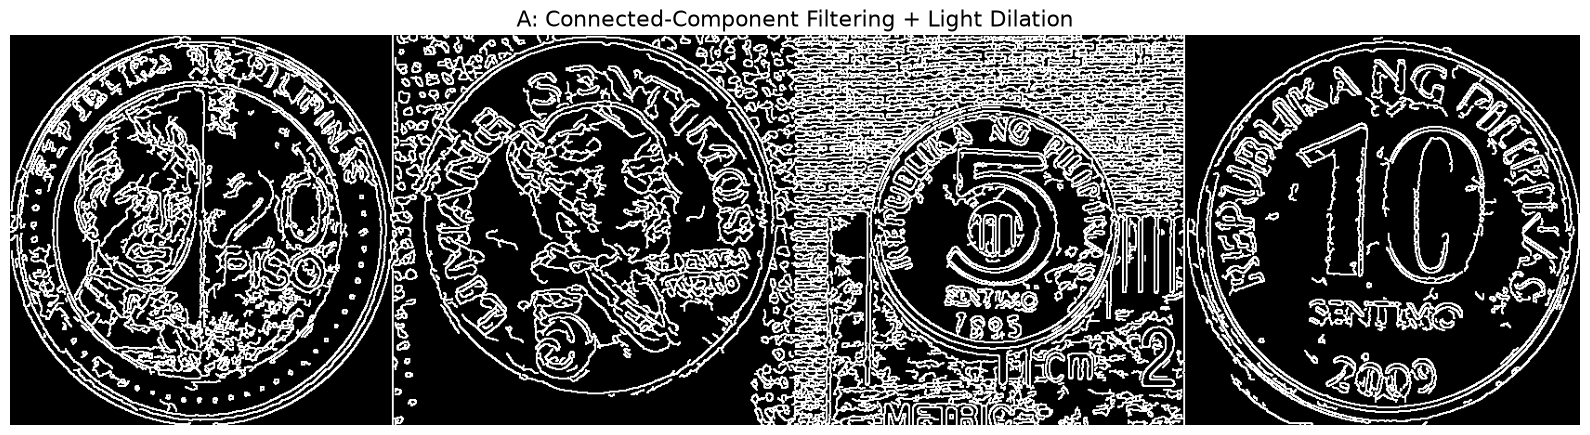

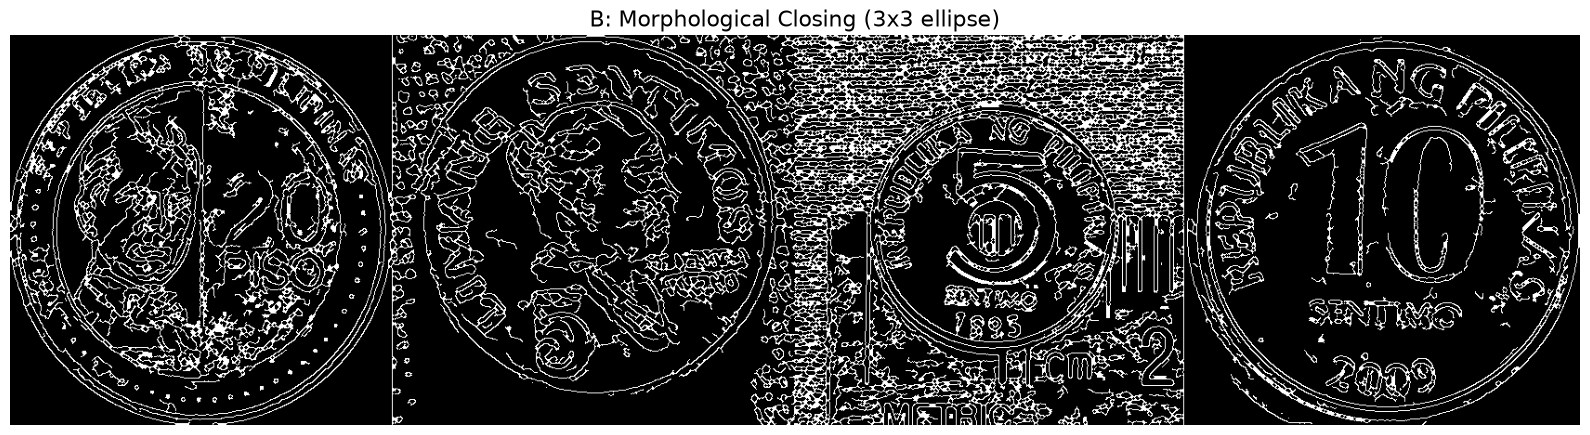

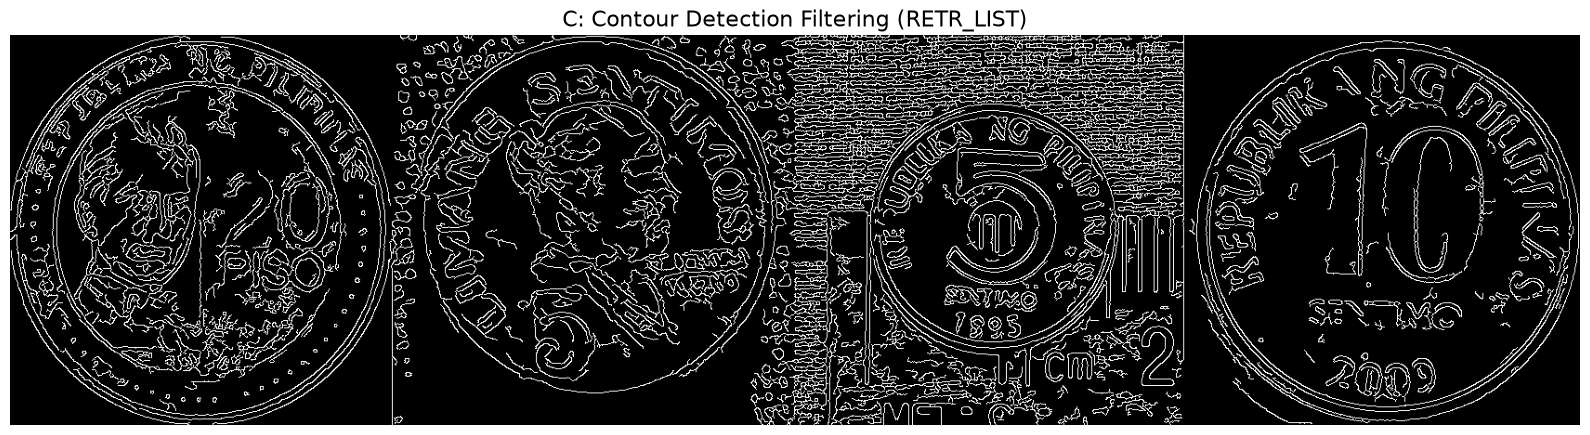

In [10]:
edges = cv2.Canny(sharpened, 40, 120)

# Connected-Component Labeling with Area-Based Filtering
n_labels, labels, stats, _ = cv2.connectedComponentsWithStats(edges, connectivity=8)
cc_clean = np.zeros_like(edges)
for i in range(1, n_labels):
    if stats[i, cv2.CC_STAT_AREA] >= 4:   # drop only 1-3 px noise specks
        cc_clean[labels == i] = 255
kernel_dilate = np.ones((2, 2), np.uint8)
cc_result = cv2.dilate(cc_clean, kernel_dilate, iterations=1)

# Morphological Closing 
kernel_morph = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
morph_result = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, kernel_morph, iterations=1)

#Contour Detection Filtering 
contours, _ = cv2.findContours(edges, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)
contour_result = np.zeros_like(edges)
for c in contours:
    if cv2.contourArea(c) > 5:
        cv2.drawContours(contour_result, [c], -1, 255, 1)

results = [
    (edges, "Raw Canny Edges (before cleaning)"),
    (cc_result, "A: Connected-Component Filtering + Light Dilation"),
    (morph_result, "B: Morphological Closing (3x3 ellipse)"),
    (contour_result, "C: Contour Detection Filtering (RETR_LIST)")
]

for image, title in results:
    plt.figure(figsize=(16, 6))
    plt.imshow(image, cmap="gray")
    plt.title(title, fontsize=16)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

Comparing the three cleaning methods: **Morphological Closing (B)** merges the raised-portrait shading into thick blobs and starts erasing thin letter strokes even at a small 3x3 kernel, and **Contour Detection Filtering (C)** thins out some of the finer denomination text since short broken strokes fall under the area threshold. 

Meanwhile, **Connected-Component Filtering + Light Dilation (A)** keeps every real edge (only 1-3 pixel isolated specks are ever removed) while still bolding the lines enough to read clearly. Thus, this method is adopted.

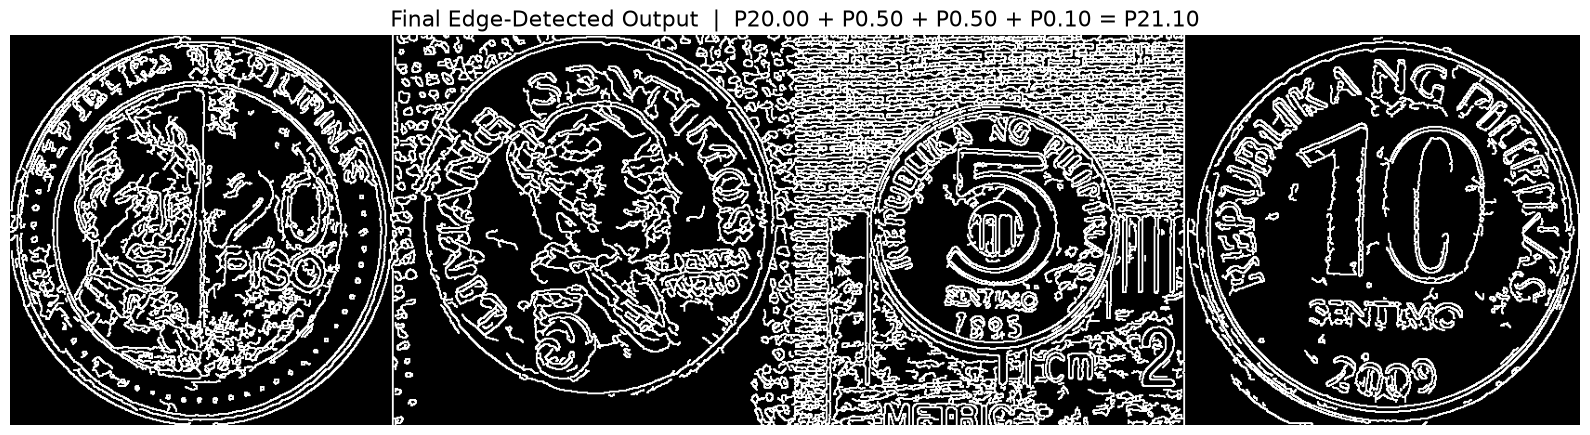

In [12]:
plt.figure(figsize=(16, 6))
plt.imshow(cc_result, cmap="gray")
plt.title("Final Edge-Detected Output  |  P20.00 + P0.50 + P0.50 + P0.10 = P21.10", fontsize=16)
plt.axis("off")
plt.tight_layout()
plt.show()

As seen in the image above, the final output shows the clean edges of the coins forming **₱21.10**. While the other methods may have removed some noise, they also compromised the integrity of the coin edges, making it difficult to read the denominations clearly. The strong edges produced by the connected-component filtering and light dilation method ensure that the coin denominations are easily identifiable, which is crucial for accurate coin detection and analysis.

On a different note, a challenge that emerged in this step was the photo of the 5 cents on top of a ruler, which caused the edge detection to pick up the ruler's edges as well; as such, the final output captures the outline of the ruler in the background as well. This highlights the importance of careful image selection and preparation to ensure that only relevant features are detected in the edge detection process.

#### **Summary**

**Coins used:** 1 x P20.00 coin, 2 x P0.50 (50-centavo) coins, 1 x P0.10 (10-sentimo) coin
&rarr; **20.00 + 0.50 + 0.50 + 0.10 = P21.10**

**Kernel used:**
- A 5x5 Gaussian kernel (weights summing to 256) for smoothing/noise suppression.
- A 3x3 sharpening kernel `[[0,-1,0],[-1,5,-1],[0,-1,0]]` for convolution/contrast boost —
  chosen over the sample notebook's center-weight-7 variant, which was found to overexpose
  the image and lose detail.

**Convolution process:** Each kernel is slid over every pixel of the grayscale image; at each position the neighborhood pixel values are multiplied element-wise by the kernel weights and summed (`cv2.filter2D`) to produce the output pixel. The Gaussian kernel averages neighboring pixels (weighted toward the center) to suppress noise, while the sharpening kernel amplifies the center pixel relative to its neighbors to emphasize edges and fine detail before edge detection.

**Edge detection method:** Three methods were tried on the sharpened image — Canny, Laplacian, and Sobel. Canny (`cv2.Canny`, thresholds 40/120) produced the cleanest, most well-defined coin edges; Laplacian and Sobel both let through more background noise and less distinct boundaries, so Canny was selected.

**How the result was improved:**
1. Median filtering removed speckle noise from the coin surface texture before any gradient-based operation could amplify it.
2. Gaussian smoothing (as a convolution) further suppressed high-frequency noise while preserving the coin's overall shape.
3. The sharpening convolution increased local contrast so the lettering and portrait details survived into the edge map instead of being lost in the blur.
4. Three cleaning methods were tried on the Canny output — connected-component area filtering, morphological closing, and contour detection filtering. Morphological closing merged fine details together and contour filtering thinned out some denomination text, so connected-component filtering (dropping only 1-3 pixel noise specks) plus a light dilation was used for the final result — producing clean circular coin boundaries with the denominations ("20 PISO", "50 SENTIMOS", "10 SENTIMO") still clearly readable, so the P21.10 total can be visually verified.
